# Toxic Comment Classification


In [ ]:
! pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 12.4 MB/s eta 0:00:00


In [ ]:
! pip install -q transformers

In [ ]:
! pip install -q sentence-transformers

Loading some libraries

In [ ]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import gensim.downloader as api
import time
import nltk
import torch


from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from nltk.tokenize import word_tokenize
from sentence_transformers import SentenceTransformer

print("GPU disponible :", torch.cuda.is_available())

GPU disponible : True


Loading the data

In [ ]:
df = pd.read_csv('/content/data.csv')
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [ ]:
df.tail()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
159566,ffe987279560d7ff,""":::::And for the second time of asking, when ...",0,0,0,0,0,0
159567,ffea4adeee384e90,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0
159568,ffee36eab5c267c9,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0
159569,fff125370e4aaaf3,And it looks like it was actually you who put ...,0,0,0,0,0,0
159570,fff46fc426af1f9a,"""\nAnd ... I really don't think you understand...",0,0,0,0,0,0


In [ ]:
data = df[["comment_text", "toxic"]].copy()

In [ ]:
data.head()

,comment_text,toxic
0,Explanation\nWhy the edits made under my usern...,0
1,D'aww! He matches this background colour I'm s...,0
2,"Hey man, I'm really not trying to edit war. It...",0
3,"""\nMore\nI can't make any real suggestions on ...",0
4,"You, sir, are my hero. Any chance you remember...",0


In [ ]:
data.tail()

,comment_text,toxic
159566,""":::::And for the second time of asking, when ...",0
159567,You should be ashamed of yourself \n\nThat is ...,0
159568,"Spitzer \n\nUmm, theres no actual article for ...",0
159569,And it looks like it was actually you who put ...,0
159570,"""\nAnd ... I really don't think you understand...",0


In [ ]:
data.shape

(159571, 2)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   comment_text  159571 non-null  object
 1   toxic         159571 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ MB


In [ ]:
data.isna().sum()

,0
comment_text,0
toxic,0


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data["toxic"].value_counts(normalize=True)

,proportion
toxic,
0,0.904156
1,0.095844


## Step 1: Preprocessing

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Tokenization

In [ ]:
data["tokens"] = data["comment_text"].apply(
    lambda x: word_tokenize(str(x).lower())
)

data[["comment_text", "tokens"]].head()

,comment_text,tokens
0,Explanation\nWhy the edits made under my usern...,"[explanation, why, the, edits, made, under, my..."
1,D'aww! He matches this background colour I'm s...,"[d'aww, !, he, matches, this, background, colo..."
2,"Hey man, I'm really not trying to edit war. It...","[hey, man, ,, i, 'm, really, not, trying, to, ..."
3,"""\nMore\nI can't make any real suggestions on ...","[``, more, i, ca, n't, make, any, real, sugges..."
4,"You, sir, are my hero. Any chance you remember...","[you, ,, sir, ,, are, my, hero, ., any, chance..."


Stop-word removal

In [ ]:
stop_words = set(stopwords.words("english"))

words_to_keep = {
    "not", "no", "nor", "n't",

}

stop_words -= words_to_keep

In [ ]:
data["tokens_no_stopwords"] = data["tokens"].apply(
    lambda toks: [t for t in toks if t not in stop_words]
)

data[
    ["comment_text", "tokens", "tokens_no_stopwords"]
].head()

,comment_text,tokens,tokens_no_stopwords
0,Explanation\nWhy the edits made under my usern...,"[explanation, why, the, edits, made, under, my...","[explanation, edits, made, username, hardcore,..."
1,D'aww! He matches this background colour I'm s...,"[d'aww, !, he, matches, this, background, colo...","[d'aww, !, matches, background, colour, 'm, se..."
2,"Hey man, I'm really not trying to edit war. It...","[hey, man, ,, i, 'm, really, not, trying, to, ...","[hey, man, ,, 'm, really, not, trying, edit, w..."
3,"""\nMore\nI can't make any real suggestions on ...","[``, more, i, ca, n't, make, any, real, sugges...","[``, ca, n't, make, real, suggestions, improve..."
4,"You, sir, are my hero. Any chance you remember...","[you, ,, sir, ,, are, my, hero, ., any, chance...","[,, sir, ,, hero, ., chance, remember, page, '..."


Special character cleaning

In [ ]:
html = {
    "br", "<", "/", "html", "style", "script", "div"
}

In [ ]:
data["tokens_clean"] = data["tokens_no_stopwords"].apply(
    lambda toks: [t for t in toks if t not in html]
)

In [ ]:
special_characters = {
    "{", "}", "[", "]", "(", ")", ";", ":",
    ".", "?", ",", "^", "/", "+", "%", "-",
    "&", "@", "#", "%", "~", "|", "\\", "_"
}

Keep *, $ and !

In [ ]:
data["tokens_clean"] = data["tokens_clean"].apply(
    lambda toks: [t for t in toks if t not in special_characters]
)

In [ ]:
data.head()

,comment_text,toxic,tokens,tokens_no_stopwords,tokens_clean
0,Explanation\nWhy the edits made under my usern...,0,"[explanation, why, the, edits, made, under, my...","[explanation, edits, made, username, hardcore,...","[explanation, edits, made, username, hardcore,..."
1,D'aww! He matches this background colour I'm s...,0,"[d'aww, !, he, matches, this, background, colo...","[d'aww, !, matches, background, colour, 'm, se...","[d'aww, !, matches, background, colour, 'm, se..."
2,"Hey man, I'm really not trying to edit war. It...",0,"[hey, man, ,, i, 'm, really, not, trying, to, ...","[hey, man, ,, 'm, really, not, trying, edit, w...","[hey, man, 'm, really, not, trying, edit, war,..."
3,"""\nMore\nI can't make any real suggestions on ...",0,"[``, more, i, ca, n't, make, any, real, sugges...","[``, ca, n't, make, real, suggestions, improve...","[``, ca, n't, make, real, suggestions, improve..."
4,"You, sir, are my hero. Any chance you remember...",0,"[you, ,, sir, ,, are, my, hero, ., any, chance...","[,, sir, ,, hero, ., chance, remember, page, '...","[sir, hero, chance, remember, page, 's]"


Stemming

In [ ]:
stemmer = PorterStemmer()

In [ ]:
import sys
sys.setrecursionlimit(5000)
data["tokens_stemmed"] = data["tokens_clean"].apply(lambda toks: [stemmer.stem(t) for t in toks])

In [ ]:
data.head()

,comment_text,toxic,tokens,tokens_no_stopwords,tokens_clean,tokens_stemmed
0,Explanation\nWhy the edits made under my usern...,0,"[explanation, why, the, edits, made, under, my...","[explanation, edits, made, username, hardcore,...","[explanation, edits, made, username, hardcore,...","[explan, edit, made, usernam, hardcor, metalli..."
1,D'aww! He matches this background colour I'm s...,0,"[d'aww, !, he, matches, this, background, colo...","[d'aww, !, matches, background, colour, 'm, se...","[d'aww, !, matches, background, colour, 'm, se...","[d'aww, !, match, background, colour, 'm, seem..."
2,"Hey man, I'm really not trying to edit war. It...",0,"[hey, man, ,, i, 'm, really, not, trying, to, ...","[hey, man, ,, 'm, really, not, trying, edit, w...","[hey, man, 'm, really, not, trying, edit, war,...","[hey, man, 'm, realli, not, tri, edit, war, 's..."
3,"""\nMore\nI can't make any real suggestions on ...",0,"[``, more, i, ca, n't, make, any, real, sugges...","[``, ca, n't, make, real, suggestions, improve...","[``, ca, n't, make, real, suggestions, improve...","[``, ca, n't, make, real, suggest, improv, won..."
4,"You, sir, are my hero. Any chance you remember...",0,"[you, ,, sir, ,, are, my, hero, ., any, chance...","[,, sir, ,, hero, ., chance, remember, page, '...","[sir, hero, chance, remember, page, 's]","[sir, hero, chanc, rememb, page, 's]"


## Step 2: Feature Engineering Based on Embeddings

## * Word Embeddings Using Word2Vec

In [ ]:
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

Collect tokens for Gensim

In [ ]:
tokens_all = list(data["tokens_stemmed"])

In [ ]:
tokens_clean = list(data["tokens_clean"])

Train a small Word2Vec model on the corpus

In [ ]:
start_time = time.time()

w2v = Word2Vec(
    sentences=tokens_all,
    vector_size=200,
    window=5,
    min_count=2,
    workers=2,
    sg=1,
    epochs=10
)

word2vec_train_time = time.time() - start_time
print("Training time:", round(word2vec_train_time, 1), "seconds")
print("Vocabulary size:", len(w2v.wv))

Training time: 455.6 seconds
Vocabulary size: 84045


In [ ]:
def doc_vector(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    if not vecs:
        return np.zeros(w2v.vector_size, dtype = np.float32)
    return np.mean(vecs, axis = 0)

In [ ]:
start_time = time.time()
X_w2v = np.vstack([doc_vector(toks) for toks in tokens_all])
word2vec_embedding_time = time.time() - start_time

print("Shape:", X_w2v.shape)
print("Embedding time:", word2vec_embedding_time, "seconds")

Shape: (159571, 200)
Embedding time: 13.842325448989868 seconds


## * Word Embeddings Using GloVe

In [ ]:
glove = api.load("glove-wiki-gigaword-100")

[==================================================] 100.0% 128.1/128.1MB downloaded


In [ ]:
print("Embedding dimension:", glove.vector_size)
print("Vocabulary size:", len(glove))

Embedding dimension: 100
Vocabulary size: 400000


In [ ]:
def glove_vector(tokens):
    vectors = [
        glove[word]
        for word in tokens
        if word in glove
    ]

    if len(vectors) == 0:
        return np.zeros(glove.vector_size)

    return np.mean(vectors, axis=0)

GloVe is pretrained: we provide tokens_clean rather than tokens_stemmed, because its
vocabulary contains only real words (amazing exists, amaz does not). The next cell
checks this.

In [ ]:
sample_clean   = [t for toks in data["tokens_clean"].head(2000)   for t in toks]
sample_stemmed = [t for toks in data["tokens_stemmed"].head(2000) for t in toks]

print("Couverture GloVe, tokens_clean   : %.1f %%" % (100 * np.mean([t in glove for t in sample_clean])))
print("Couverture GloVe, tokens_stemmed : %.1f %%" % (100 * np.mean([t in glove for t in sample_stemmed])))

Couverture GloVe, tokens_clean   : 94.4 %
Couverture GloVe, tokens_stemmed : 76.7 %


In [ ]:
start_time = time.time()

X_glove = np.vstack(
    data["tokens_clean"].apply(glove_vector)
)

glove_embedding_time = time.time() - start_time

print("Shape:", X_glove.shape)
print("Embedding time:", glove_embedding_time, "seconds")

Shape: (159571, 100)
Embedding time: 13.182765245437622 seconds


## * Word Embeddings Using fastText

In [ ]:
from gensim.models import FastText

In [ ]:
start_time = time.time()

ft = FastText(sentences = tokens_clean,
    vector_size = 200,
    window = 5,
    min_count = 2,
    workers = 2,
    sg = 1,
    epochs = 10)

fasttext_train_time = time.time() - start_time
print("Training time:", round(fasttext_train_time, 1), "seconds")

Training time: 1128.2 seconds


In [ ]:
def ft_vector(tokens):
    vecs = [ft.wv[w] for w in tokens if w in ft.wv]
    if not vecs:
        return np.zeros(ft.vector_size, dtype = np.float32)
    return np.mean(vecs, axis = 0)

In [ ]:
start_time = time.time()
X_ft = np.vstack([ft_vector(toks) for toks in tokens_clean])
ft_embedding_time = time.time() - start_time

print("Shape:", X_ft.shape)
print("Embedding time:", ft_embedding_time, "seconds")

Shape: (159571, 200)
Embedding time: 22.31551456451416 seconds


# * Sentence Embeddings Using MiniLM

In [ ]:
minilm = SentenceTransformer("all-MiniLM-L6-v2")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
print("Embedding dimension:", minilm.get_sentence_embedding_dimension())

Embedding dimension: 384


/tmp/ipykernel_2116/3461843056.py:1: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", minilm.get_sentence_embedding_dimension())


In [ ]:
start_time = time.time()

X_minilm = minilm.encode(
    data["comment_text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

minilm_embedding_time = time.time() - start_time

Batches:   0%|          | 0/2494 [00:00<?, ?it/s]

In [ ]:
print("Shape:", X_minilm.shape)
print("Embedding time:", minilm_embedding_time, "seconds")

Shape: (159571, 384)
Embedding time: 189.4759237766266 seconds


MiniLM receives the raw text: it has its own tokenizer and needs punctuation,
capitalization, and stop words to understand the sentence. The takeaway is clear: the
more modern the models become, the less manual preprocessing is needed.

Save the matrices to avoid recalculating everything.

In [ ]:
np.save("X_w2v.npy", X_w2v)
np.save("X_glove.npy", X_glove)
np.save("X_ft.npy", X_ft)
np.save("X_minilm.npy", X_minilm)
print("ok")

ok


### Loading the matrices

In [ ]:
X_w2v    = np.load("/content/X_w2v.npy")
X_glove  = np.load("/content/X_glove.npy")
X_ft     = np.load("/content/X_ft.npy")
X_minilm = np.load("/content/X_minilm.npy")

for nom, X in [("Word2Vec", X_w2v), ("GloVe", X_glove),
               ("fastText", X_ft), ("MiniLM", X_minilm)]:
    print("%-10s %s  %s" % (nom, X.shape, X.dtype))

assert all(X.shape[0] == len(data) for X in [X_w2v, X_glove, X_ft, X_minilm]), \
       "Le nombre de lignes ne correspond pas a data"
print("\nAlignement verifie :", len(data), "lignes")

Word2Vec   (159571, 200)  float32
GloVe      (159571, 100)  float64
fastText   (159571, 200)  float32
MiniLM     (159571, 384)  float32

Alignement verifie : 159571 lignes


Times measured during the initial embedding generation with a T4 GPU

In [ ]:
word2vec_train_time     = 455.6
word2vec_embedding_time = 13.8
glove_embedding_time    = 13.2
fasttext_train_time     = 1128.2
ft_embedding_time       = 22.3
minilm_embedding_time   = 189.5

## Step 3: Train/Test Split

We split the data only once, using the row indices. All approaches (embeddings,
transformers, LLMs) are therefore evaluated on exactly the same comments, making the
comparison fair. random_state = 42 ensures reproducibility.

In [ ]:
y = data["toxic"].values
indices = np.arange(len(data))

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

y_train = y[idx_train]
y_test  = y[idx_test]

print("train:", idx_train.shape, "| test:", idx_test.shape)
print("taux de toxiques dans le test: %.3f" % y_test.mean())

train: (127656,) | test: (31915,)
taux de toxiques dans le test: 0.096


### Evaluation subset for the slower approaches

The LLM in Step 6 takes about 0.2 seconds per comment, so it cannot be run on all
31,915 test comments. We therefore sample a balanced subset of 500 comments
(250 toxic, 250 non-toxic) from the test set. This is the only scope where all six
approaches can be compared with one another.

Two references to keep distinct:
- pos_eval: the positions of these 500 comments in the test set (for slicing predictions);
- idx_eval: their indices in data (for retrieving the raw text).

In [ ]:
N_EVAL = 500

rng = np.random.RandomState(42)
pos_toxic     = np.where(y_test == 1)[0]
pos_non_toxic = np.where(y_test == 0)[0]

pos_eval = np.concatenate([
    rng.choice(pos_toxic,     N_EVAL // 2, replace=False),
    rng.choice(pos_non_toxic, N_EVAL // 2, replace=False)
])
pos_eval = np.sort(pos_eval)

idx_eval = idx_test[pos_eval]
y_eval   = y_test[pos_eval]

print("sous-ensemble:", len(pos_eval), "| taux de toxiques: %.2f" % y_eval.mean())

sous-ensemble: 500 | taux de toxiques: 0.50


Finally, two lists to collect the results as we go: one for the full test set,
one for the 500-comment subset.

* results for the full test set (31,915 comments)
* results_eval for the balanced subset (500 comments)

In [ ]:
results      = []
results_eval = []

temps_encodage = {
    "Word2Vec": word2vec_embedding_time,
    "GloVe":    glove_embedding_time,
    "fastText": ft_embedding_time,
    "MiniLM":   minilm_embedding_time,
}

## Step 4: Modeling

Here, we use two different models (logistic regression and SVM) on each of our vectors.

## Shared Evaluation Function

In [ ]:
from sklearn.metrics import precision_score, recall_score

def evaluer(nom, clf, X, nom_representation):

    start_time = time.time()
    clf.fit(X[idx_train], y_train)
    train_time = time.time() - start_time

    start_time = time.time()
    pred = clf.predict(X[idx_test])
    if hasattr(clf, "predict_proba"):
        score = clf.predict_proba(X[idx_test])[:, 1]
    else:
        score = clf.decision_function(X[idx_test])
    predict_time = time.time() - start_time

    ms = (temps_encodage[nom_representation] / len(data)
          + predict_time / len(idx_test)) * 1000

    print("=====", nom, "=====")
    print(classification_report(y_test, pred, target_names=["non toxic", "toxic"], digits=3))
    print("AUC: %.3f | entrainement: %.1f s | cout: %.3f ms/commentaire"
          % (roc_auc_score(y_test, score), train_time, ms))

    results.append({
        "model": nom,
        "precision_toxic": precision_score(y_test, pred, zero_division=0),
        "recall_toxic":    recall_score(y_test, pred),
        "f1_toxic":        f1_score(y_test, pred),
        "auc":             roc_auc_score(y_test, score),
        "encodage_s":      temps_encodage[nom_representation],
        "train_time_s":    train_time,
        "ms_per_comment":  ms,
    })

    results_eval.append({
        "model": nom,
        "precision_toxic": precision_score(y_eval, pred[pos_eval], zero_division=0),
        "recall_toxic":    recall_score(y_eval, pred[pos_eval]),
        "f1_toxic":        f1_score(y_eval, pred[pos_eval]),
        "accuracy":        (y_eval == pred[pos_eval]).mean(),
        "ms_per_comment":  ms,
    })

    return pred, score

### The four Logistic Regression Models

In [ ]:
pred_w2v,    score_w2v    = evaluer("Word2Vec + LogReg", LogisticRegression(max_iter=1000), X_w2v,    "Word2Vec")
pred_glove,  score_glove  = evaluer("GloVe + LogReg",    LogisticRegression(max_iter=1000), X_glove,  "GloVe")
pred_ft,     score_ft     = evaluer("fastText + LogReg", LogisticRegression(max_iter=1000), X_ft,     "fastText")
pred_minilm, score_minilm = evaluer("MiniLM + LogReg",   LogisticRegression(max_iter=1000), X_minilm, "MiniLM")

===== Word2Vec + LogReg =====
              precision    recall  f1-score   support

   non toxic      0.960     0.988     0.973     28856
       toxic      0.839     0.607     0.704      3059

    accuracy                          0.951     31915
   macro avg      0.899     0.797     0.839     31915
weighted avg      0.948     0.951     0.948     31915

AUC: 0.962 | entrainement: 2.1 s | cout: 0.091 ms/commentaire
===== GloVe + LogReg =====
              precision    recall  f1-score   support

   non toxic      0.944     0.985     0.964     28856
       toxic      0.757     0.448     0.563      3059

    accuracy                          0.933     31915
   macro avg      0.851     0.716     0.763     31915
weighted avg      0.926     0.933     0.925     31915

AUC: 0.929 | entrainement: 2.5 s | cout: 0.084 ms/commentaire
===== fastText + LogReg =====
              precision    recall  f1-score   support

   non toxic      0.961     0.987     0.974     28856
       toxic      0.840   

### The four Linear SVMs

In [ ]:
pred_w2v_svm,   score_w2v_svm   = evaluer("Word2Vec + LinearSVM", LinearSVC(), X_w2v,    "Word2Vec")
pred_glove_svm, score_glove_svm = evaluer("GloVe + LinearSVM",    LinearSVC(), X_glove,  "GloVe")
pred_ft_svm,    score_ft_svm    = evaluer("fastText + LinearSVM", LinearSVC(), X_ft,     "fastText")
pred_svm,       score_svm       = evaluer("MiniLM + LinearSVM",   LinearSVC(), X_minilm, "MiniLM")

===== Word2Vec + LinearSVM =====
              precision    recall  f1-score   support

   non toxic      0.956     0.991     0.973     28856
       toxic      0.871     0.571     0.690      3059

    accuracy                          0.951     31915
   macro avg      0.913     0.781     0.831     31915
weighted avg      0.948     0.951     0.946     31915

AUC: 0.963 | entrainement: 4.2 s | cout: 0.088 ms/commentaire
===== GloVe + LinearSVM =====
              precision    recall  f1-score   support

   non toxic      0.940     0.989     0.964     28856
       toxic      0.802     0.405     0.538      3059

    accuracy                          0.933     31915
   macro avg      0.871     0.697     0.751     31915
weighted avg      0.927     0.933     0.923     31915

AUC: 0.929 | entrainement: 3.0 s | cout: 0.084 ms/commentaire
===== fastText + LinearSVM =====
              precision    recall  f1-score   support

   non toxic      0.958     0.991     0.974     28856
       toxic     

### Hyperparameter Search

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score

grille = {
    "C": [0.01, 0.1, 1, 10, 100]
}

decoupage = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

mesures = {
    "recall":    "recall",
    "precision": "precision",
    "f1":        "f1",
    "f2":        make_scorer(fbeta_score, beta=2),
}

def chercher_meilleur(nom_representation, X):
    recherche = GridSearchCV(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        grille,
        scoring=mesures,
        refit="recall",
        cv=decoupage,
        n_jobs=-1,
        verbose=1,
    )

    start_time = time.time()
    recherche.fit(X[idx_train], y_train)
    print("Recherche terminee en %.0f s" % (time.time() - start_time))

    detail = pd.DataFrame(recherche.cv_results_)[
        ["param_C", "mean_test_recall", "mean_test_precision",
         "mean_test_f1", "mean_test_f2", "std_test_recall"]
    ].sort_values("mean_test_recall", ascending=False)
    print(detail.round(3).to_string(index=False))

    print("\nMeilleurs parametres :", recherche.best_params_)
    print("Rappel moyen en validation croisee : %.3f\n" % recherche.best_score_)

    return evaluer(nom_representation + " + LogReg (optimisee)",
                   recherche.best_estimator_, X, nom_representation)

## Running the Search

In [ ]:
pred_w2v_opt,    score_w2v_opt    = chercher_meilleur("Word2Vec", X_w2v)
pred_glove_opt,  score_glove_opt  = chercher_meilleur("GloVe",    X_glove)
pred_ft_opt,     score_ft_opt     = chercher_meilleur("fastText", X_ft)
pred_minilm_opt, score_minilm_opt = chercher_meilleur("MiniLM",   X_minilm)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Recherche terminee en 18 s
 param_C  mean_test_recall  mean_test_precision  mean_test_f1  mean_test_f2  std_test_recall
   10.00             0.876                0.524         0.656         0.773            0.006
    1.00             0.876                0.526         0.657         0.773            0.006
  100.00             0.876                0.525         0.656         0.773            0.006
    0.10             0.874                0.529         0.659         0.773            0.007
    0.01             0.855                0.525         0.651         0.759            0.004

Meilleurs parametres : {'C': 10}
Rappel moyen en validation croisee : 0.876

===== Word2Vec + LogReg (optimisee) =====
              precision    recall  f1-score   support

   non toxic      0.987     0.918     0.951     28856
       toxic      0.532     0.884     0.665      3059

    accuracy                          0.914     31915
   macro avg     

## Model Summary

In [ ]:
colonnes = ["model", "precision_toxic", "recall_toxic", "f1_toxic", "auc",
            "encodage_s", "train_time_s", "ms_per_comment"]

print(pd.DataFrame(results)[colonnes]
      .sort_values("recall_toxic", ascending=False)
      .round(3).to_string(index=False))

                        model  precision_toxic  recall_toxic  f1_toxic   auc  encodage_s  train_time_s  ms_per_comment
fastText + LogReg (optimisee)            0.541         0.890     0.673 0.969        22.3         3.049           0.142
  MiniLM + LogReg (optimisee)            0.500         0.885     0.639 0.962       189.5         4.084           1.195
Word2Vec + LogReg (optimisee)            0.532         0.884     0.665 0.965        13.8         1.599           0.090
   GloVe + LogReg (optimisee)            0.411         0.829     0.550 0.931        13.2         2.238           0.084
              MiniLM + LogReg            0.825         0.627     0.713 0.961       189.5         5.179           1.193
           MiniLM + LinearSVM            0.846         0.624     0.718 0.962       189.5         9.113           1.192
            fastText + LogReg            0.840         0.623     0.716 0.967        22.3         4.803           0.145
            Word2Vec + LogReg            0.839  

### Effect of Class Weighting

In [ ]:
results      = pd.DataFrame(results).drop_duplicates(subset="model", keep="last").to_dict("records")
results_eval = pd.DataFrame(results_eval).drop_duplicates(subset="model", keep="last").to_dict("records")

print("Modeles conserves :", len(results))
print(pd.DataFrame(results)["model"].tolist())

Modeles conserves : 12
['Word2Vec + LogReg', 'GloVe + LogReg', 'fastText + LogReg', 'MiniLM + LogReg', 'Word2Vec + LinearSVM', 'GloVe + LinearSVM', 'fastText + LinearSVM', 'MiniLM + LinearSVM', 'Word2Vec + LogReg (optimisee)', 'GloVe + LogReg (optimisee)', 'fastText + LogReg (optimisee)', 'MiniLM + LogReg (optimisee)']


In [ ]:
comparaison = (pd.DataFrame(results)
               .drop_duplicates(subset="model", keep="last")
               .set_index("model"))

for rep in ["Word2Vec", "GloVe", "fastText", "MiniLM"]:
    nom_base = rep + " + LogReg"
    nom_opt  = rep + " + LogReg (optimisee)"

    if nom_base not in comparaison.index or nom_opt not in comparaison.index:
        print("%-10s  modele manquant, cellule non executee" % rep)
        continue

    base = comparaison.loc[nom_base]
    opt  = comparaison.loc[nom_opt]
    print("%-10s  rappel %.3f -> %.3f   precision %.3f -> %.3f   F1 %.3f -> %.3f"
          % (rep, base["recall_toxic"], opt["recall_toxic"],
             base["precision_toxic"], opt["precision_toxic"],
             base["f1_toxic"], opt["f1_toxic"]))

print("\nPart de commentaires signales par les modeles optimises")
print("(taux reel de toxiques dans le test : %.3f)" % y_test.mean())
for nom, pred in [("Word2Vec", pred_w2v_opt), ("GloVe", pred_glove_opt),
                  ("fastText", pred_ft_opt),  ("MiniLM", pred_minilm_opt)]:
    print("%-10s %.3f" % (nom, pred.mean()))

Word2Vec    rappel 0.607 -> 0.884   precision 0.839 -> 0.532   F1 0.704 -> 0.665
GloVe       rappel 0.448 -> 0.829   precision 0.757 -> 0.411   F1 0.563 -> 0.550
fastText    rappel 0.623 -> 0.890   precision 0.840 -> 0.541   F1 0.716 -> 0.673
MiniLM      rappel 0.627 -> 0.885   precision 0.825 -> 0.500   F1 0.713 -> 0.639

Part de commentaires signales par les modeles optimises
(taux reel de toxiques dans le test : 0.096)
Word2Vec   0.159
GloVe      0.193
fastText   0.158
MiniLM     0.170


## Step 5: Transformers

We do not train anything here. We use a DistilBERT model already fine-tuned for toxicity
detection, through a Hugging Face pipeline, directly on the raw text.

In [ ]:
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

clf_hf = pipeline(
    "text-classification",
    model="martin-ha/toxic-comment-model",
    device=device,
    truncation=True,
    max_length=256
)

print(clf_hf.model.config.id2label)

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  268MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/403 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

{0: 'non-toxic', 1: 'toxic'}


In [ ]:
TOXIC_LABELS = {"TOXIC", "LABEL_1"}

def hf_pred(texts, batch_size=64, chunk=2000):
    scores = []
    for i in range(0, len(texts), chunk):
        outs = clf_hf([str(t) for t in texts[i:i + chunk]], batch_size=batch_size, top_k=None)
        for o in outs:
            hit = [d["score"] for d in o if d["label"].upper().replace("-", "_") in TOXIC_LABELS]
            scores.append(hit[0])
        print("   ", min(i + chunk, len(texts)), "/", len(texts))
    p_toxic = np.array(scores)
    return (p_toxic >= 0.5).astype(int), p_toxic

## Prediction on the Entire Test Set

In [ ]:
texts_test = data["comment_text"].values[idx_test]

start_time = time.time()
pred_hf, score_hf = hf_pred(texts_test)
hf_predict_time = time.time() - start_time

print(classification_report(y_test, pred_hf, target_names=["non toxic", "toxic"], digits=3))
print("AUC:", round(roc_auc_score(y_test, score_hf), 3))
print("Predict time:", round(hf_predict_time, 1), "s")

hf_ms = hf_predict_time / len(idx_test) * 1000

results.append({
    "model": "DistilBERT (zero-shot)",
    "precision_toxic": precision_score(y_test, pred_hf, zero_division=0),
    "recall_toxic":    recall_score(y_test, pred_hf),
    "f1_toxic":        f1_score(y_test, pred_hf),
    "auc":             roc_auc_score(y_test, score_hf),
    "encodage_s":      0.0,
    "train_time_s":    0.0,
    "ms_per_comment":  hf_ms,
})

results_eval.append({
    "model": "DistilBERT (zero-shot)",
    "precision_toxic": precision_score(y_eval, pred_hf[pos_eval], zero_division=0),
    "recall_toxic":    recall_score(y_eval, pred_hf[pos_eval]),
    "f1_toxic":        f1_score(y_eval, pred_hf[pos_eval]),
    "accuracy":        (y_eval == pred_hf[pos_eval]).mean(),
    "ms_per_comment":  hf_ms,
})

    2000 / 31915
    4000 / 31915
    6000 / 31915
    8000 / 31915
    10000 / 31915
    12000 / 31915
    14000 / 31915
    16000 / 31915
    18000 / 31915


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


    20000 / 31915
    22000 / 31915
    24000 / 31915
    26000 / 31915
    28000 / 31915
    30000 / 31915
    31915 / 31915
              precision    recall  f1-score   support

   non toxic      0.961     0.988     0.974     28856
       toxic      0.841     0.618     0.712      3059

    accuracy                          0.952     31915
   macro avg      0.901     0.803     0.843     31915
weighted avg      0.949     0.952     0.949     31915

AUC: 0.961
Predict time: 238.3 s


Where do the transformer and the best embedding-based model disagree? Useful for the presentation.

In [ ]:
desaccords = np.where(pred_ft_opt != pred_hf)[0][:5]

for i in desaccords:
    print("vrai =", y_test[i], "| fastText =", pred_ft_opt[i], "| DistilBERT =", pred_hf[i],
          "(p = %.2f)" % score_hf[i])
    print(texts_test[i][:300])
    print("-" * 90)

vrai = 0 | fastText = 1 | DistilBERT = 0 (p = 0.00)
i will back again someday.
------------------------------------------------------------------------------------------
vrai = 1 | fastText = 1 | DistilBERT = 0 (p = 0.04)
yo, dog, mind yer own busyness... whoops... dick war yer only busness mankind 41.42.137.67
------------------------------------------------------------------------------------------
vrai = 0 | fastText = 1 | DistilBERT = 0 (p = 0.21)
But then he wouldn't be able to sit here arguing with everyone about trivialities on wikipedain't. If only I had a nickel for every user on wikipedain't that acted like a retard posting useless garbage more than half of the entire world disagrees with then I would be a very rich person today. I wish
------------------------------------------------------------------------------------------
vrai = 1 | fastText = 0 | DistilBERT = 1 (p = 0.51)
Even if I'm leaving this bullshit of Wikipedia forever, I will observe as well what kind of negotiat

## Step 6: Prompt Engineering

We query an LLM instead of training a classifier. We use FLAN-T5-base.

Three prompts: zero-shot, few-shot, and role prompting.

Two technical points: FLAN-T5 is an encoder-decoder model, so the correct pipeline is
text2text-generation (not text-generation, which only rewrites the prompt). We also set
do_sample=False so that classification is deterministic and reproducible.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, set_seed
set_seed(42)



device_torch = "cuda" if torch.cuda.is_available() else "cpu"

tok_llm = AutoTokenizer.from_pretrained("google/flan-t5-base")
mod_llm = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(device_torch).eval()

@torch.no_grad()
def gen(prompts, max_new_tokens=20, do_sample=False, temperature=1.0,
        batch_size=16, truncation=True):

    seul = isinstance(prompts, str)
    liste = [prompts] if seul else list(prompts)

    sorties = []
    for i in range(0, len(liste), batch_size):
        enc = tok_llm(liste[i:i + batch_size], return_tensors="pt",
                      padding=True, truncation=True, max_length=512).to(device_torch)
        out = mod_llm.generate(**enc,
                               max_new_tokens=max_new_tokens,
                               do_sample=do_sample,
                               temperature=temperature if do_sample else None)
        sorties += [{"generated_text": t}
                    for t in tok_llm.batch_decode(out, skip_special_tokens=True)]

    return sorties[0:1] if seul else sorties

print("FLAN-T5 chargé sur", device_torch)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 chargé sur cuda


In [ ]:
MAX_CHARS = 800

def nettoyer(texte, limite):
    return " ".join(str(texte).split())[:limite]

def prompt_zero_shot(comment):
    return f"""Is the following comment toxic? A toxic comment is rude, disrespectful, insulting, obscene, threatening or hateful. Answer only yes or no.

Comment: {nettoyer(comment, MAX_CHARS)}
Answer:"""

In [ ]:
N_EXEMPLES_PAR_CLASSE = 2
MAX_CHARS_EXEMPLE     = 250

longueurs  = data["comment_text"].astype(str).str.len().values
candidats  = idx_train[(longueurs[idx_train] >= 100) & (longueurs[idx_train] <= 250)]
cand_toxic = candidats[y[candidats] == 1]
cand_non   = candidats[y[candidats] == 0]

rng_ex  = np.random.RandomState(42)
i_toxic = rng_ex.choice(cand_toxic, N_EXEMPLES_PAR_CLASSE, replace=False)
i_non   = rng_ex.choice(cand_non,   N_EXEMPLES_PAR_CLASSE, replace=False)

def nettoyer(texte, limite):
    return " ".join(str(texte).split())[:limite]

exemples_corpus = []
for k in range(N_EXEMPLES_PAR_CLASSE):
    exemples_corpus.append((nettoyer(data["comment_text"].iloc[i_non[k]],   MAX_CHARS_EXEMPLE), "no"))
    exemples_corpus.append((nettoyer(data["comment_text"].iloc[i_toxic[k]], MAX_CHARS_EXEMPLE), "yes"))

for texte, label in exemples_corpus:
    print("[%s] %s\n" % (label, texte))

[no] This merger tag should be removed since it has had eight months to gestate and has failed to rally support. The commentors are generally opposed to this merge. A merger should only be performed if there is a clear consensus to merge.

[yes] Don't Blame ME You know you're wrong, M-Man. And don't blame me for making you feel stupid - you've GOT to be used to it. Maybe you thought you could hide it on the internet - anonyminity and all that. Nope, sorry, that doesn't work.

[no] I think that that is the point. Had I been blocked by anyone else it would actually mean something. But having the town's rogue cop giving you the once over is just unremarkable.

[yes] FUCK U! I AINT G0TTA DO SHIT AND FUCK WIKIPEDIA YALL WEAK MOTHER FUCKERS GET UR INFO RIGHT AND LOCK ALL UR SHIT CUZ YOUR INFO IS ALL WRONG SO SUCK MY DICK AND FUCK U BITCH AND MIND UR BUSINESS OR U CAN SUCK MY DICK OR KISS MY ASS!



In [ ]:
def prompt_few_shot(comment):
    bloc = ""
    for texte, label in exemples_corpus:
        bloc += "Comment: %s\nAnswer: %s\n\n" % (texte, label)

    return f"""Is the following comment toxic? A toxic comment is rude, disrespectful, insulting, obscene, threatening or hateful. Answer only yes or no.

{bloc}Comment: {nettoyer(comment, MAX_CHARS)}
Answer:"""

In [ ]:
p = prompt_few_shot(data["comment_text"].iloc[idx_test[0]])
n_tokens = len(tok_llm(p)["input_ids"])

print("Longueur du prompt : %d tokens" % n_tokens)
if n_tokens > 500:
    print(">>> TROP LONG, mettez MAX_CHARS_EXEMPLE = 150 dans la cellule 1")
else:
    print(">>> OK")

print(p)

Longueur du prompt : 402 tokens
>>> OK
Is the following comment toxic? A toxic comment is rude, disrespectful, insulting, obscene, threatening or hateful. Answer only yes or no.

Comment: This merger tag should be removed since it has had eight months to gestate and has failed to rally support. The commentors are generally opposed to this merge. A merger should only be performed if there is a clear consensus to merge.
Answer: no

Comment: Don't Blame ME You know you're wrong, M-Man. And don't blame me for making you feel stupid - you've GOT to be used to it. Maybe you thought you could hide it on the internet - anonyminity and all that. Nope, sorry, that doesn't work.
Answer: yes

Comment: I think that that is the point. Had I been blocked by anyone else it would actually mean something. But having the town's rogue cop giving you the once over is just unremarkable.
Answer: no

Comment: FUCK U! I AINT G0TTA DO SHIT AND FUCK WIKIPEDIA YALL WEAK MOTHER FUCKERS GET UR INFO RIGHT AND LOCK A

In [ ]:
def prompt_role(comment):
    return f"""You are a Wikipedia content moderator. Your policy is to flag a comment as toxic when it contains insults, obscenity, identity attacks, threats or harassment. Disagreement, criticism and strong opinions are NOT toxic. Apply the policy to the comment below and answer only yes or no.

Comment: {nettoyer(comment, MAX_CHARS)}
Answer:"""

Testing the three prompts on a toxic comment from the test set.

In [ ]:
exemple = data["comment_text"].values[idx_eval][y_eval == 1][0]
print(exemple[:400])
print("=" * 90)

for nom, prompt_fn in [("zero-shot", prompt_zero_shot),
                       ("few-shot",  prompt_few_shot),
                       ("role",      prompt_role)]:
    sortie = gen(prompt_fn(exemple), max_new_tokens=5, do_sample=False)
    print(nom, "->", sortie[0]["generated_text"])

"

The dick who is editing with policy is also editing out of policy, by being arrogant, lazy and fucking up the functionality of the Image Workshop. His worrying obsession with NFCC#9 is his excuse for being a twat. he is deliberately making the workshop non-functional. For the IW to work properly we have to be able to either see or be able to link to the image being requested. Now Mr Dick esq co
zero-shot -> no
few-shot -> Answer: no
role -> no


Effect of temperature: a high temperature makes generation unstable, which is exactly
what we want to avoid in a classification task.

In [ ]:
p = "Write a one-sentence rule explaining when a Wikipedia comment should be removed."

for t in [1.5, 0.2]:
    print("temperature =", t, "->", gen(p, max_new_tokens=40, do_sample=True, temperature=t)[0]["generated_text"])

print("greedy (do_sample=False) ->", gen(p, max_new_tokens=40, do_sample=False)[0]["generated_text"])

temperature = 1.5 -> Beg what it is asking. A comment can be unintentionally removed, in order to demonstrate the power. Only people under 100 or over 18 want someone in the audience to take his/
temperature = 0.2 -> If a comment is deemed inappropriate, it should be removed.
greedy (do_sample=False) -> When a comment is deleted, it will be removed from the site.


In [ ]:
def llm_pred(texts, prompt_fn, batch_size=16):
    prompts = [prompt_fn(t) for t in texts]
    outs = gen(prompts, batch_size=batch_size, max_new_tokens=5, do_sample=False, truncation=True)
    reponses = [o[0]["generated_text"] if isinstance(o, list) else o["generated_text"] for o in outs]

    labels = []
    for r in reponses:
        r = r.strip().lower().replace("answer:", "").strip()
        labels.append(1 if r.startswith(("yes", "toxic")) else 0)

    return np.array(labels), reponses

Evaluation of the three prompts on the 500-comment subset.

In [ ]:
texts_eval = data["comment_text"].values[idx_eval]

for nom, prompt_fn in [("FLAN-T5 zero-shot", prompt_zero_shot),
                       ("FLAN-T5 few-shot",  prompt_few_shot),
                       ("FLAN-T5 role",      prompt_role)]:

    start_time = time.time()
    pred_llm, reponses = llm_pred(texts_eval, prompt_fn)
    llm_predict_time = time.time() - start_time

    print("#####", nom)
    print("reponses brutes:", pd.Series([r.strip().lower() for r in reponses]).value_counts().to_dict())
    print(classification_report(y_eval, pred_llm, target_names=["non toxic", "toxic"], digits=3))
    print("AUC:", round(roc_auc_score(y_eval, pred_llm), 3))
    print("Predict time:", round(llm_predict_time, 1), "s\n")

    results_eval.append({
        "model": nom,
        "precision_toxic": precision_score(y_eval, pred_llm, zero_division=0),
        "recall_toxic":    recall_score(y_eval, pred_llm),
        "f1_toxic":        f1_score(y_eval, pred_llm),
        "accuracy":        (y_eval == pred_llm).mean(),
        "ms_per_comment":  llm_predict_time / len(idx_eval) * 1000,
    })

##### FLAN-T5 zero-shot
reponses brutes: {'no': 287, 'yes': 213}
              precision    recall  f1-score   support

   non toxic      0.787     0.904     0.842       250
       toxic      0.887     0.756     0.816       250

    accuracy                          0.830       500
   macro avg      0.837     0.830     0.829       500
weighted avg      0.837     0.830     0.829       500

AUC: 0.83
Predict time: 12.1 s

##### FLAN-T5 few-shot
reponses brutes: {'no': 326, 'yes': 121, 'answer: no': 43, 'answer: yes': 10}
              precision    recall  f1-score   support

   non toxic      0.648     0.956     0.772       250
       toxic      0.916     0.480     0.630       250

    accuracy                          0.718       500
   macro avg      0.782     0.718     0.701       500
weighted avg      0.782     0.718     0.701       500

AUC: 0.718
Predict time: 26.7 s

##### FLAN-T5 role
reponses brutes: {'no': 318, 'yes': 182}
              precision    recall  f1-score   support



The LLM returns only a label (yes / no), not a probability. The AUC calculated here on
hard labels is therefore equivalent to balanced accuracy; it is not strictly comparable
to the AUCs from models that output probabilities.

## Step 7: Comparing the Approaches

In [ ]:
cols_complet = ["model", "precision_toxic", "recall_toxic", "f1_toxic", "auc",
                "encodage_s", "train_time_s", "ms_per_comment"]

tableau_complet = (pd.DataFrame(results)[cols_complet]
                   .sort_values("recall_toxic", ascending=False))
print("### Test complet (", len(idx_test), "commentaires )")
tableau_complet.round(3)

### Test complet ( 31915 commentaires )


,model,precision_toxic,recall_toxic,f1_toxic,auc,encodage_s,train_time_s,ms_per_comment
10,fastText + LogReg (optimisee),0.541,0.890,0.673,0.969,22.3,3.049,0.142
11,MiniLM + LogReg (optimisee),0.500,0.885,0.639,0.962,189.5,4.084,1.195
8,Word2Vec + LogReg (optimisee),0.532,0.884,0.665,0.965,13.8,1.599,0.090
9,GloVe + LogReg (optimisee),0.411,0.829,0.550,0.931,13.2,2.238,0.084
3,MiniLM + LogReg,0.825,0.627,0.713,0.961,189.5,5.179,1.193
7,MiniLM + LinearSVM,0.846,0.624,0.718,0.962,189.5,9.113,1.192
2,fastText + LogReg,0.840,0.623,0.716,0.967,22.3,4.803,0.145
12,DistilBERT (zero-shot),0.841,0.618,0.712,0.961,0.0,0.000,7.466
0,Word2Vec + LogReg,0.839,0.607,0.704,0.962,13.8,2.147,0.091
6,fastText + LinearSVM,0.871,0.590,0.704,0.967,22.3,4.499,0.142


In [ ]:
cols_eval = ["model", "precision_toxic", "recall_toxic", "f1_toxic",
             "accuracy", "ms_per_comment"]

tableau_eval = (pd.DataFrame(results_eval)[cols_eval]
                .sort_values("recall_toxic", ascending=False))
print("### Sous-ensemble equilibre (", len(idx_eval), "commentaires )")
tableau_eval.round(3)

### Sous-ensemble equilibre ( 500 commentaires )


,model,precision_toxic,recall_toxic,f1_toxic,accuracy,ms_per_comment
11,MiniLM + LogReg (optimisee),0.914,0.888,0.901,0.902,1.195
8,Word2Vec + LogReg (optimisee),0.927,0.868,0.897,0.900,0.090
10,fastText + LogReg (optimisee),0.938,0.848,0.891,0.896,0.142
9,GloVe + LogReg (optimisee),0.900,0.828,0.862,0.868,0.084
13,FLAN-T5 zero-shot,0.887,0.756,0.816,0.830,24.127
2,fastText + LogReg,0.982,0.648,0.781,0.818,0.145
3,MiniLM + LogReg,0.970,0.636,0.768,0.808,1.193
12,DistilBERT (zero-shot),0.981,0.628,0.766,0.808,7.466
7,MiniLM + LinearSVM,0.975,0.620,0.758,0.802,1.192
0,Word2Vec + LogReg,0.981,0.620,0.760,0.804,0.091


In [ ]:
meilleur_rappel = tableau_complet.iloc[0]
meilleur_f1     = tableau_complet.sort_values("f1_toxic", ascending=False).iloc[0]

print("Meilleur rappel : %-35s rappel = %.3f | precision = %.3f | F1 = %.3f"
      % (meilleur_rappel["model"], meilleur_rappel["recall_toxic"],
         meilleur_rappel["precision_toxic"], meilleur_rappel["f1_toxic"]))
print("Meilleur F1     : %-35s rappel = %.3f | precision = %.3f | F1 = %.3f"
      % (meilleur_f1["model"], meilleur_f1["recall_toxic"],
         meilleur_f1["precision_toxic"], meilleur_f1["f1_toxic"]))

Meilleur rappel : fastText + LogReg (optimisee)       rappel = 0.890 | precision = 0.541 | F1 = 0.673
Meilleur F1     : MiniLM + LinearSVM                  rappel = 0.624 | precision = 0.846 | F1 = 0.718


In [ ]:
tableau_complet.to_csv("projet2_resultats_test_complet.csv", index=False)
tableau_eval.to_csv("projet2_resultats_sous_ensemble.csv", index=False)
print("fichiers enregistrés")

fichiers enregistrés


## Visualizing the Main Metrics

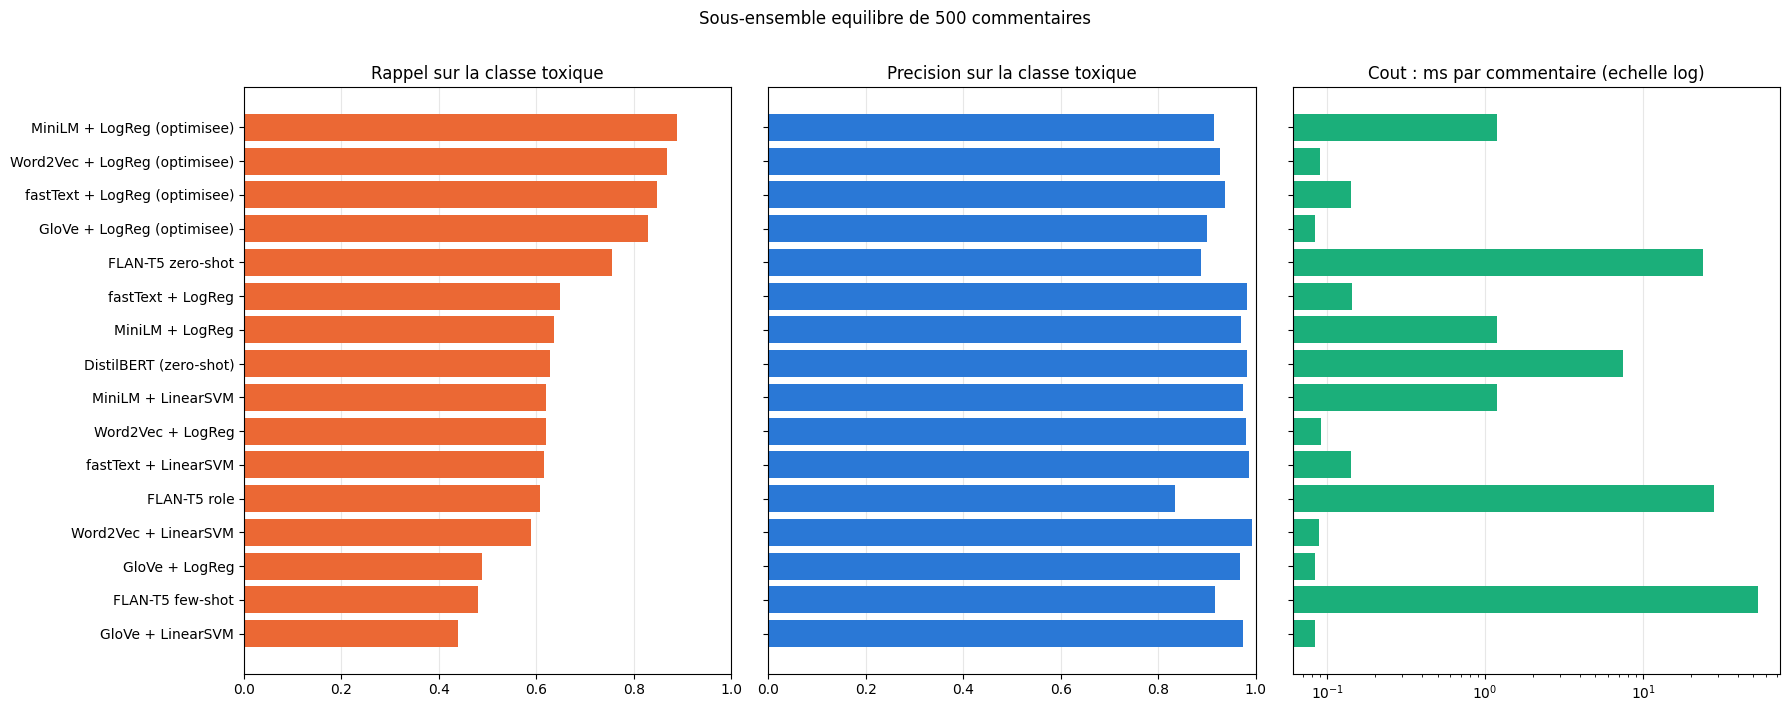

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

d = tableau_eval.sort_values("recall_toxic")

axes[0].barh(d["model"], d["recall_toxic"], color="#eb6834")
axes[0].set_title("Rappel sur la classe toxique")
axes[0].set_xlim(0, 1)

axes[1].barh(d["model"], d["precision_toxic"], color="#2a78d6")
axes[1].set_title("Precision sur la classe toxique")
axes[1].set_xlim(0, 1)

axes[2].barh(d["model"], d["ms_per_comment"], color="#1baf7a")
axes[2].set_title("Cout : ms par commentaire (echelle log)")
axes[2].set_xscale("log")

for ax in axes:
    ax.grid(alpha=0.3, axis="x")
    ax.set_axisbelow(True)

fig.suptitle("Sous-ensemble equilibre de %d commentaires" % len(idx_eval), y=1.01)
plt.tight_layout()
plt.savefig("projet2_comparaison.png", dpi=150, bbox_inches="tight")
plt.show()

## Visualizing the Precision/Recall Trade-off

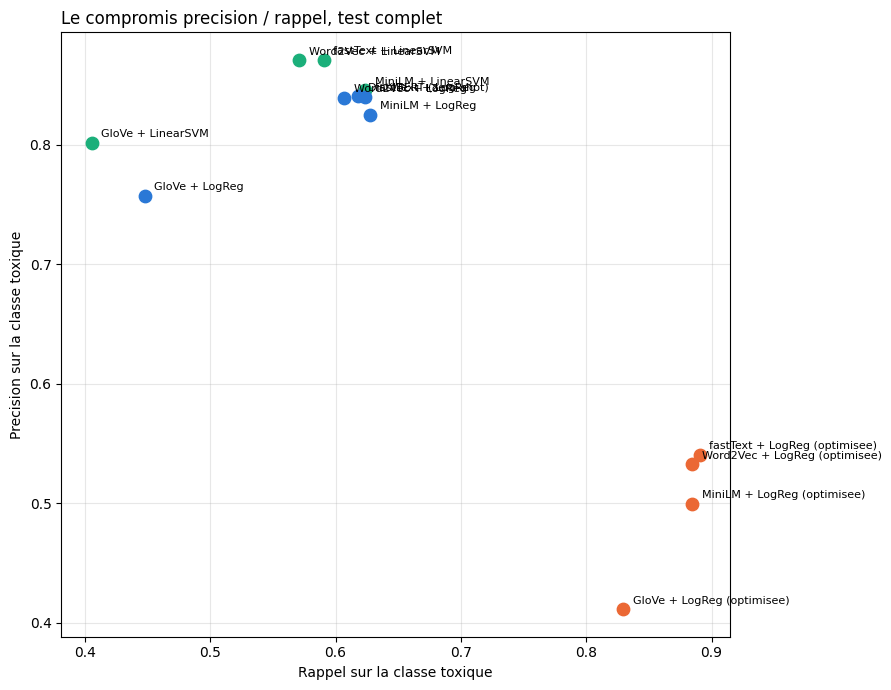

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))

for _, ligne in tableau_complet.iterrows():
    if "optimisee" in ligne["model"]:
        couleur = "#eb6834"
    elif "SVM" in ligne["model"]:
        couleur = "#1baf7a"
    else:
        couleur = "#2a78d6"
    ax.scatter(ligne["recall_toxic"], ligne["precision_toxic"],
               s=80, color=couleur, zorder=3)
    ax.annotate(ligne["model"], (ligne["recall_toxic"], ligne["precision_toxic"]),
                xytext=(7, 4), textcoords="offset points", fontsize=8)

ax.set_xlabel("Rappel sur la classe toxique")
ax.set_ylabel("Precision sur la classe toxique")
ax.set_title("Le compromis precision / rappel, test complet", loc="left")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("projet2_precision_rappel.png", dpi=150, bbox_inches="tight")
plt.show()

## ROC Curve for the Models

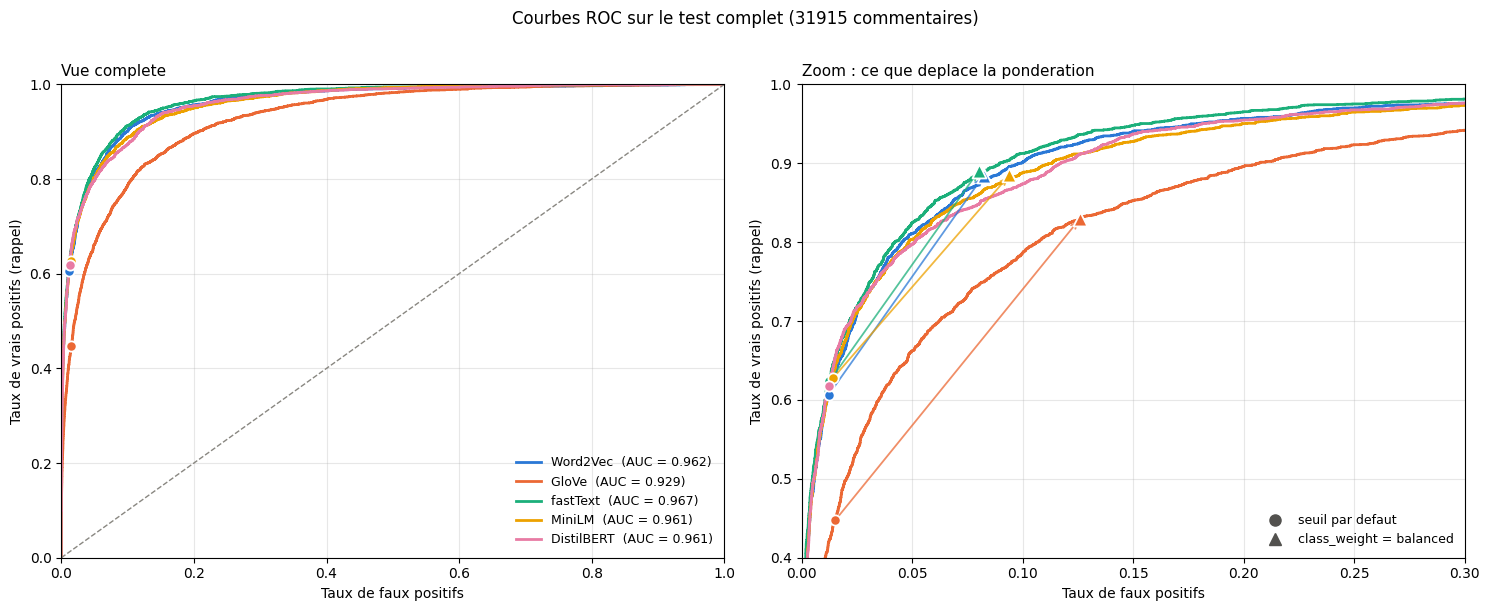

In [ ]:
from sklearn.metrics import roc_curve, confusion_matrix
from matplotlib.lines import Line2D

courbes = [
    ("Word2Vec",   score_w2v,    pred_w2v,    pred_w2v_opt,    "#2a78d6"),
    ("GloVe",      score_glove,  pred_glove,  pred_glove_opt,  "#eb6834"),
    ("fastText",   score_ft,     pred_ft,     pred_ft_opt,     "#1baf7a"),
    ("MiniLM",     score_minilm, pred_minilm, pred_minilm_opt, "#eda100"),
    ("DistilBERT", score_hf,     pred_hf,     None,            "#e87ba4"),
]

def point(y_vrai, pred):
    """Coordonnees (taux de faux positifs, rappel) du seuil reellement utilise."""
    tn, fp, fn, tp = confusion_matrix(y_vrai, pred).ravel()
    return fp / (fp + tn), tp / (tp + fn)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, xmax, ymin, titre in [(axes[0], 1.00, 0.00, "Vue complete"),
                              (axes[1], 0.30, 0.40, "Zoom : ce que deplace la ponderation")]:

    for nom, score, pred_def, pred_opt, couleur in courbes:
        fpr, tpr, _ = roc_curve(y_test, score)
        ax.plot(fpr, tpr, color=couleur, linewidth=2,
                label="%s  (AUC = %.3f)" % (nom, roc_auc_score(y_test, score)))

        x, y = point(y_test, pred_def)
        ax.scatter([x], [y], s=55, marker="o", color=couleur, zorder=5,
                   edgecolor="white", linewidth=1.3)

        if ax is axes[1] and pred_opt is not None:
            x2, y2 = point(y_test, pred_opt)
            ax.annotate("", xy=(x2, y2), xytext=(x, y),
                        arrowprops=dict(arrowstyle="->", color=couleur,
                                        linewidth=1.3, alpha=0.75))
            ax.scatter([x2], [y2], s=100, marker="^", color=couleur, zorder=6,
                       edgecolor="white", linewidth=1.3)

    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#898781")
    ax.set_xlim(0, xmax)
    ax.set_ylim(ymin, 1.0)
    ax.set_xlabel("Taux de faux positifs")
    ax.set_ylabel("Taux de vrais positifs (rappel)")
    ax.set_title(titre, fontsize=11, loc="left")
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

axes[0].legend(loc="lower right", frameon=False, fontsize=9)

marqueurs = [Line2D([], [], marker="o", linestyle="", color="#52514e", markersize=8),
             Line2D([], [], marker="^", linestyle="", color="#52514e", markersize=9)]
axes[1].legend(marqueurs, ["seuil par defaut", "class_weight = balanced"],
               loc="lower right", frameon=False, fontsize=9)

fig.suptitle("Courbes ROC sur le test complet (%d commentaires)" % len(y_test),
             y=1.01, fontsize=12)
plt.tight_layout()
plt.savefig("projet2_roc_test_complet.png", dpi=200, bbox_inches="tight")
plt.show()

## ROC Curve on the Subset to Compare All Models

FLAN-T5 zero-shot ok
FLAN-T5 few-shot ok
FLAN-T5 role ok


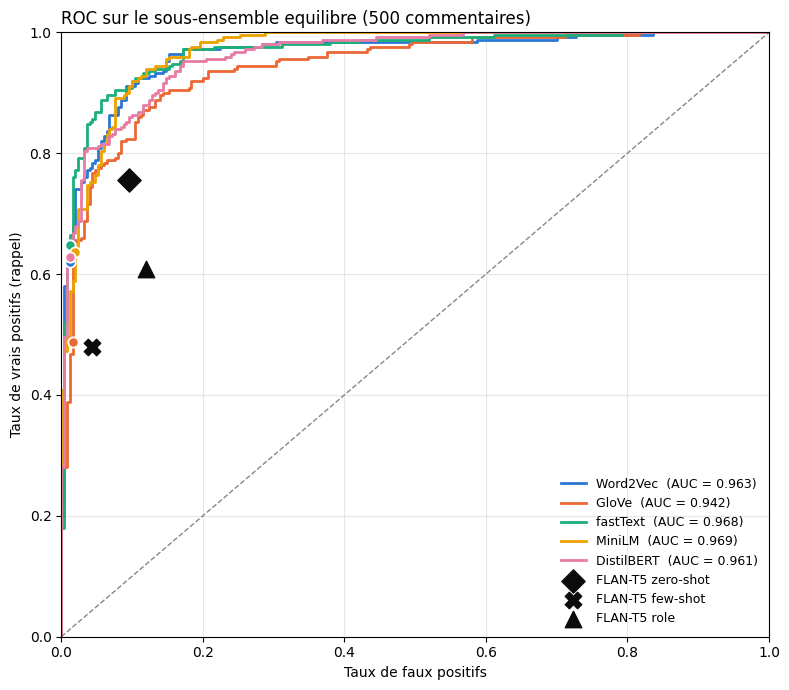

In [ ]:
if "preds_llm" not in globals():
    preds_llm = {}
    for nom, prompt_fn in [("FLAN-T5 zero-shot", prompt_zero_shot),
                           ("FLAN-T5 few-shot",  prompt_few_shot),
                           ("FLAN-T5 role",      prompt_role)]:
        preds_llm[nom], _ = llm_pred(texts_eval, prompt_fn)
        print(nom, "ok")

fig, ax = plt.subplots(figsize=(8, 7))

for nom, score, pred_def, pred_opt, couleur in courbes:
    fpr, tpr, _ = roc_curve(y_eval, score[pos_eval])
    ax.plot(fpr, tpr, color=couleur, linewidth=2,
            label="%s  (AUC = %.3f)" % (nom, roc_auc_score(y_eval, score[pos_eval])))

    x, y = point(y_eval, pred_def[pos_eval])
    ax.scatter([x], [y], s=55, marker="o", color=couleur, zorder=5,
               edgecolor="white", linewidth=1.3)


for (nom, pred_llm), marqueur in zip(preds_llm.items(), ["D", "X", "^"]):
    x, y = point(y_eval, pred_llm)
    ax.scatter([x], [y], s=140, marker=marqueur, color="#0b0b0b",
               zorder=6, label=nom)

ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#898781")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs (rappel)")
ax.set_title("ROC sur le sous-ensemble equilibre (%d commentaires)" % len(y_eval),
             fontsize=12, loc="left")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("projet2_roc_sous_ensemble.png", dpi=200, bbox_inches="tight")
plt.show()

## We decided to try a larger LLM (GPT-5.2) at this stage, using zero-shot, few-shot, and prompt engineering to assess its performance

## * Setting Up the Environment to Call GPT-5.2

In [ ]:
import os
from google.colab import userdata
from openai import OpenAI

cle = userdata.get('OPENAI_API_KEY')
print("longueur :", len(cle), "| espaces ou retour a la ligne en trop :", cle != cle.strip())

client = OpenAI(api_key=cle.strip())

try:
    print([m.id for m in client.models.list() if m.id.startswith("gpt")][:10])
except Exception as e:
    print(type(e).__name__, ":", str(e)[:300])

longueur : 166 | espaces ou retour a la ligne en trop : True
['gpt-5-codex', 'gpt-realtime-mini', 'gpt-4-turbo-2024-04-09', 'gpt-realtime-2', 'gpt-realtime-2025-08-28', 'gpt-audio-2025-08-28', 'gpt-4o-mini-2024-07-18', 'gpt-5.5-pro-2026-04-23', 'gpt-5.2', 'gpt-4o-2024-11-20']


## Calling GPT-5.2

In [ ]:
GPT_MODEL = "gpt-5.2"

PARAMS_MODERNE   = {"max_completion_tokens": 256}
PARAMS_CLASSIQUE = {"max_tokens": 10, "temperature": 0}

def tester_signature():
    for nom, p in [("moderne", PARAMS_MODERNE), ("classique", PARAMS_CLASSIQUE)]:
        try:
            r = client.chat.completions.create(
                model=GPT_MODEL,
                messages=[{"role": "user", "content": "Answer only yes or no. Is 2 + 2 equal to 4?"}],
                **p)
            contenu = r.choices[0].message.content
            print("signature %s -> reponse : %r" % (nom, contenu))
            if contenu and contenu.strip():
                return p
            print("   reponse vide, on essaie l'autre signature")
        except Exception as e:
            print("signature %s refusee : %s" % (nom, str(e)[:150]))
    return None

PARAMS = tester_signature()
print("\nPARAMS retenus :", PARAMS)

signature moderne -> reponse : 'Yes'

PARAMS retenus : {'max_completion_tokens': 256}


## * Setting Up the LLM Function to Decide Whether a Comment Is Toxic

In [ ]:
from concurrent.futures import ThreadPoolExecutor
import time as chrono

def appel_unique(prompt, essais=4):
    for k in range(essais):
        try:
            r = client.chat.completions.create(
                model=GPT_MODEL,
                messages=[{"role": "user", "content": prompt}],
                **PARAMS)
            return r.choices[0].message.content
        except Exception as e:
            if k == essais - 1:
                print("echec:", str(e)[:120])
                return ""
            chrono.sleep(2 ** k)

def llm_pred_openai(texts, prompt_fn, workers=8):
    prompts = [prompt_fn(t) for t in texts]
    with ThreadPoolExecutor(max_workers=workers) as ex:
        reponses = list(ex.map(appel_unique, prompts))

    labels = []
    for r in reponses:
        r = str(r).strip().lower().replace("answer:", "").strip()
        labels.append(1 if r.startswith(("yes", "toxic")) else 0)

    return np.array(labels), reponses

## * Testing the Function on 50 Comments with a Zero-Shot Prompt

In [ ]:
pred_test, rep_test = llm_pred_openai(texts_eval[:50], prompt_zero_shot)
print(pd.Series([str(r).strip().lower() for r in rep_test]).value_counts().to_dict())
print(classification_report(y_eval[:50], pred_test, target_names=["non toxic", "toxic"], digits=3))

{'yes': 40, 'no': 10}
              precision    recall  f1-score   support

   non toxic      1.000     0.714     0.833        14
       toxic      0.900     1.000     0.947        36

    accuracy                          0.920        50
   macro avg      0.950     0.857     0.890        50
weighted avg      0.928     0.920     0.915        50



## * Testing the LLM Function on the 500 Comments

In [ ]:
for nom, prompt_fn in [("GPT-5 zero-shot", prompt_zero_shot),
                       ("GPT-5 few-shot",  prompt_few_shot),
                       ("GPT-5 role",      prompt_role)]:

    start_time = chrono.time()
    pred_gpt, reponses = llm_pred_openai(texts_eval, prompt_fn)
    gpt_time = chrono.time() - start_time

    print("#####", nom)
    print("reponses brutes:", pd.Series([str(r).strip().lower() for r in reponses]).value_counts().to_dict())
    print(classification_report(y_eval, pred_gpt, target_names=["non toxic", "toxic"], digits=3))
    print("AUC:", round(roc_auc_score(y_eval, pred_gpt), 3))
    print("Temps:", round(gpt_time, 1), "s\n")

    results_eval.append({
        "model": nom,
        "precision_toxic": precision_score(y_eval, pred_gpt, zero_division=0),
        "recall_toxic":    recall_score(y_eval, pred_gpt),
        "f1_toxic":        f1_score(y_eval, pred_gpt),
        "accuracy":        (y_eval == pred_gpt).mean(),
        "ms_per_comment":  gpt_time / len(idx_eval) * 1000,
    })

##### GPT-5 zero-shot
reponses brutes: {'yes': 289, 'no': 211}
              precision    recall  f1-score   support

   non toxic      0.976     0.824     0.894       250
       toxic      0.848     0.980     0.909       250

    accuracy                          0.902       500
   macro avg      0.912     0.902     0.901       500
weighted avg      0.912     0.902     0.901       500

AUC: 0.902
Temps: 53.1 s

##### GPT-5 few-shot
reponses brutes: {'yes': 273, 'no': 227}
              precision    recall  f1-score   support

   non toxic      0.969     0.880     0.922       250
       toxic      0.890     0.972     0.929       250

    accuracy                          0.926       500
   macro avg      0.930     0.926     0.926       500
weighted avg      0.930     0.926     0.926       500

AUC: 0.926
Temps: 52.2 s

##### GPT-5 role
reponses brutes: {'yes': 262, 'no': 238}
              precision    recall  f1-score   support

   non toxic      0.958     0.912     0.934       250
  

## Comparing All Models (Including GPT-5.2)

In [ ]:
def famille(nom):
    if nom.startswith("GPT"):     return "LLM externe (API)"
    if nom.startswith("FLAN-T5"): return "LLM local"
    if "DistilBERT" in nom:       return "Transformer"
    return "Embeddings + classifieur"

COULEURS = {
    "Embeddings + classifieur": "#2a78d6",
    "Transformer":              "#eb6834",
    "LLM local":                "#1baf7a",
    "LLM externe (API)":        "#eda100",
}

comparaison = (pd.DataFrame(results_eval)
               .drop_duplicates(subset="model", keep="last")
               .copy())
comparaison["famille"] = comparaison["model"].apply(famille)
comparaison = comparaison.sort_values("recall_toxic", ascending=False)

cols = ["model", "famille", "precision_toxic", "recall_toxic",
        "f1_toxic", "accuracy", "ms_per_comment"]

print(comparaison[cols].round(3).to_string(index=False))
comparaison.to_csv("projet2_comparaison_finale.csv", index=False)

                        model                  famille  precision_toxic  recall_toxic  f1_toxic  accuracy  ms_per_comment
              GPT-5 zero-shot        LLM externe (API)            0.848         0.980     0.909     0.902         106.198
               GPT-5 few-shot        LLM externe (API)            0.890         0.972     0.929     0.926         104.451
                   GPT-5 role        LLM externe (API)            0.916         0.960     0.938     0.936         105.583
  MiniLM + LogReg (optimisee) Embeddings + classifieur            0.914         0.888     0.901     0.902           1.195
Word2Vec + LogReg (optimisee) Embeddings + classifieur            0.927         0.868     0.897     0.900           0.090
fastText + LogReg (optimisee) Embeddings + classifieur            0.938         0.848     0.891     0.896           0.142
   GloVe + LogReg (optimisee) Embeddings + classifieur            0.900         0.828     0.862     0.868           0.084
            FLAN-T5 zero

## Visual Comparison

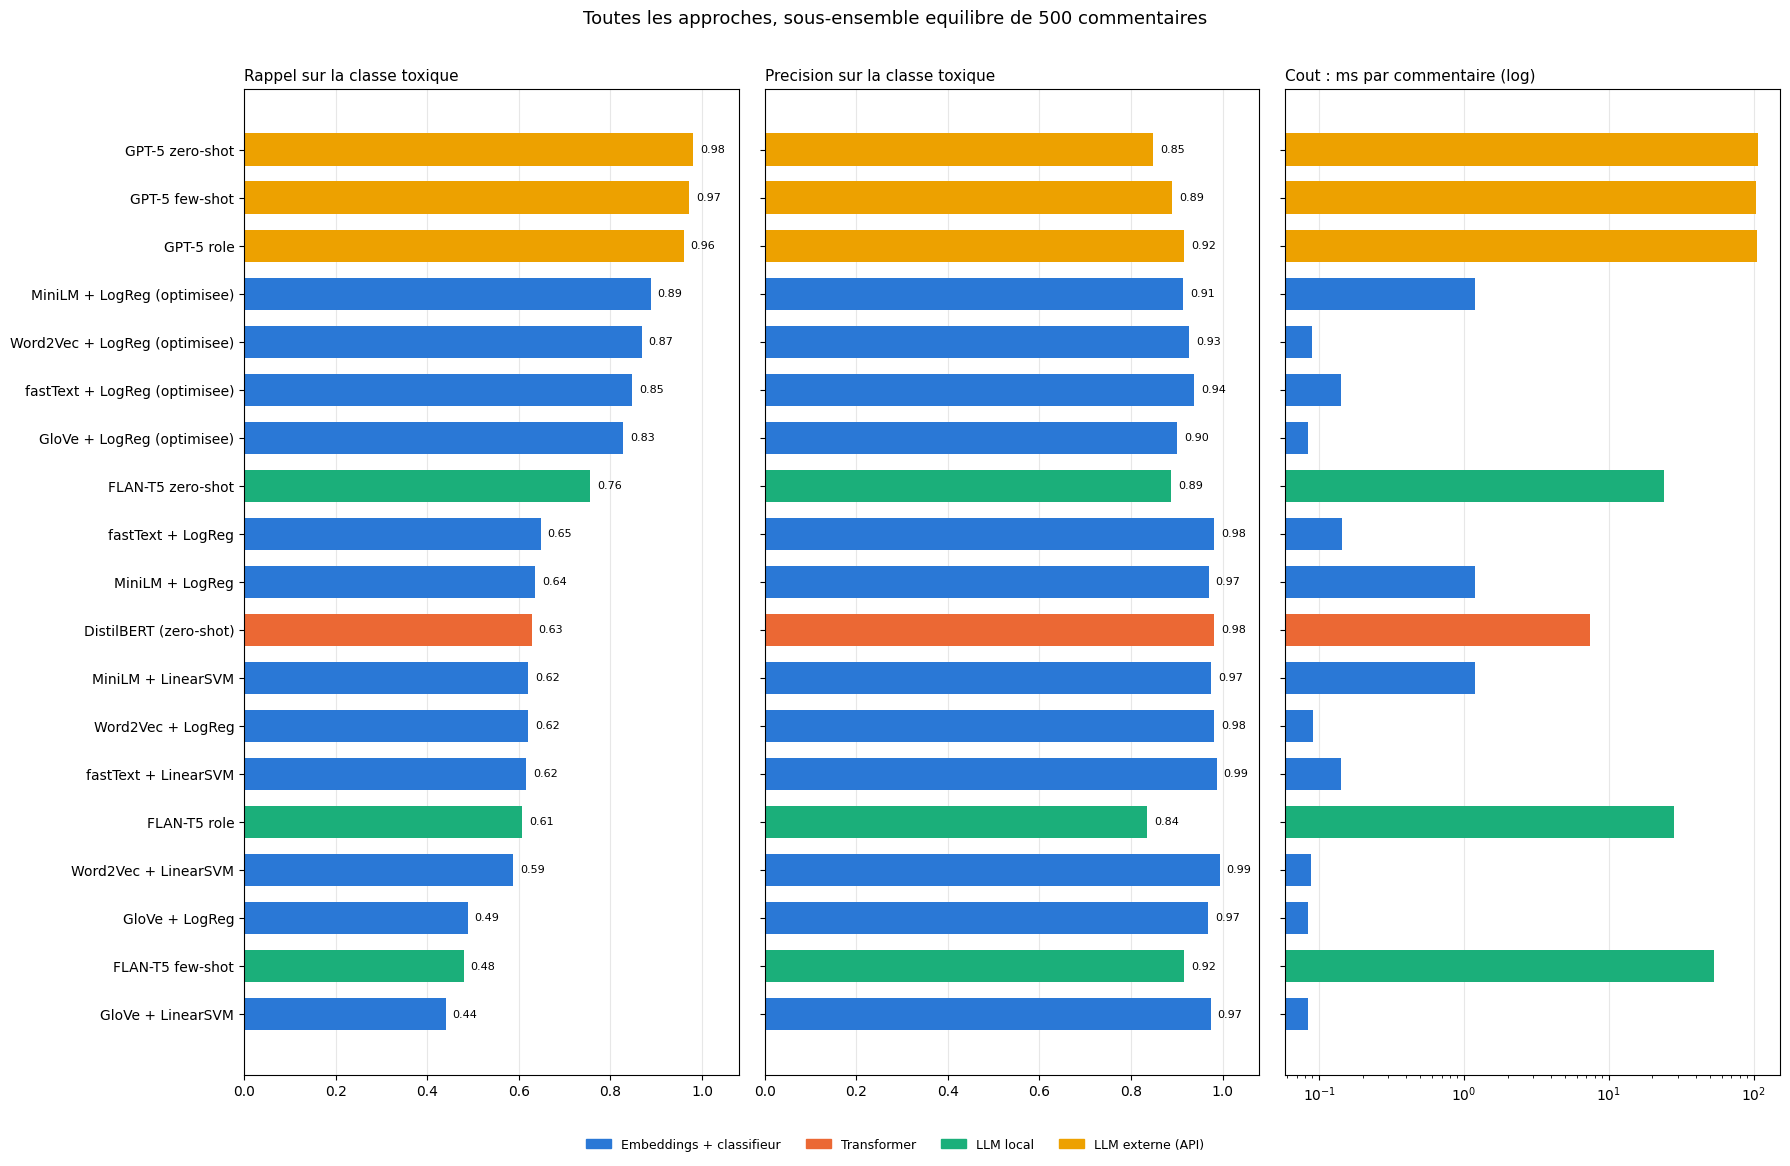

In [ ]:
from matplotlib.patches import Patch

d = comparaison.sort_values("recall_toxic")
couleurs = [COULEURS[f] for f in d["famille"]]

fig, axes = plt.subplots(1, 3, figsize=(18, 0.42 * len(d) + 3), sharey=True)

for ax, col, titre, log in [
        (axes[0], "recall_toxic",    "Rappel sur la classe toxique",    False),
        (axes[1], "precision_toxic", "Precision sur la classe toxique", False),
        (axes[2], "ms_per_comment",  "Cout : ms par commentaire (log)", True)]:

    ax.barh(d["model"], d[col], color=couleurs, height=0.68)
    ax.set_title(titre, fontsize=11, loc="left")
    if log:
        ax.set_xscale("log")
    else:
        ax.set_xlim(0, 1.08)
        for i, v in enumerate(d[col]):
            ax.text(v + 0.015, i, "%.2f" % v, va="center", fontsize=8)
    ax.grid(alpha=0.3, axis="x")
    ax.set_axisbelow(True)

legende = [Patch(color=c, label=f) for f, c in COULEURS.items()]
fig.legend(handles=legende, loc="lower center", bbox_to_anchor=(0.5, -0.04),
           ncol=4, frameon=False, fontsize=9)

fig.suptitle("Toutes les approches, sous-ensemble equilibre de %d commentaires" % len(idx_eval),
             y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig("projet2_comparaison_finale.png", dpi=200, bbox_inches="tight")
plt.show()

## A Brief Comparison Between GPT-5.2 and FLAN-T5

In [ ]:
meilleur = comparaison.iloc[0]
print("Meilleur rappel : %s" % meilleur["model"])
print("   rappel %.3f | precision %.3f | F1 %.3f | %.2f ms par commentaire\n"
      % (meilleur["recall_toxic"], meilleur["precision_toxic"],
         meilleur["f1_toxic"], meilleur["ms_per_comment"]))

print("Les trois strategies de prompt, par modele")
print(comparaison[comparaison["model"].str.contains("FLAN-T5|GPT")]
      [["model", "precision_toxic", "recall_toxic", "f1_toxic", "ms_per_comment"]]
      .round(3).to_string(index=False))

Meilleur rappel : GPT-5 zero-shot
   rappel 0.980 | precision 0.848 | F1 0.909 | 106.20 ms par commentaire

Les trois strategies de prompt, par modele
            model  precision_toxic  recall_toxic  f1_toxic  ms_per_comment
  GPT-5 zero-shot            0.848         0.980     0.909         106.198
   GPT-5 few-shot            0.890         0.972     0.929         104.451
       GPT-5 role            0.916         0.960     0.938         105.583
FLAN-T5 zero-shot            0.887         0.756     0.816          24.127
     FLAN-T5 role            0.835         0.608     0.704          28.241
 FLAN-T5 few-shot            0.916         0.480     0.630          53.325
